# IPL 2025 Player Analysis



1. Import pandas and numpy
2. Load datasets
3. Display top 5 records of both dataframes (bat_df and bowl_df)
4. Display dimensions of dataset using shape and columns keyword
5. Check for missing values
6. Display top 10 batsman (sort by runs)
7. Display top 10 bowlers  (sort by wkt)
8. Calculate Runs scored only by 4's and 6's
9. Filter Bowlers with Good Economy(ECO<7) and Strike Rate(SR<20)
10. Merge bat_df and bowl_df
11. Display all rounder player with runs > 200 and wkt >10


In [73]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
bat_df=pd.read_csv('/Users/gouravpandey/Downloads/coachX/Python/IPL Analysis Project/IPL_2025/IPL2025Batters.csv')
bowl_df=pd.read_csv('/Users/gouravpandey/Downloads/coachX/Python/IPL Analysis Project/IPL_2025/IPL2025Bowlers.csv') 
# Preview Data
bat_df.head()
bowl_df.head()

,Player Name,Team,WKT,MAT,INN,OVR,RUNS,BBI,AVG,ECO,SR,4W,5W
0,Prasidh Krishna,GT,25,15,15,59.0,488,41/4,19.52,8.27,14.16,1,0
1,Noor Ahmad,CSK,24,14,14,50.0,408,18/4,17.00,8.16,12.50,2,0
2,Josh Hazlewood,RCB,22,12,12,44.0,386,33/4,17.54,8.77,12.00,1,0
3,Trent Boult,MI,22,16,16,57.4,517,26/4,23.50,8.96,15.72,1,0
4,Arshdeep Singh,PBKS,21,17,16,58.2,518,16/3,24.66,8.88,16.66,0,0


## Dataset Overview

In [13]:
# Display shapes and column names
print("Batting Data Shape:", )
print(bat_df.shape)

print("Bowling Data Shape:",)
print(bowl_df.shape)

print("Batting Columns:",)
print(bat_df.columns)

print("Bowling Columns:",)
print(bowl_df.columns)

Batting Data Shape:
(156, 14)
Bowling Data Shape:
(108, 13)
Batting Columns:
Index(['Player Name', 'Team', 'Runs', 'Matches', 'Inn', 'No', 'HS', 'AVG',
       'BF', 'SR', '100s', '50s', '4s', '6s'],
      dtype='str')
Bowling Columns:
Index(['Player Name', 'Team', 'WKT', 'MAT', 'INN', 'OVR', 'RUNS', 'BBI', 'AVG',
       'ECO', 'SR', '4W', '5W'],
      dtype='str')


In [20]:
# Check for missing values
print("Missing values in batting data:")
print(bat_df.isnull().sum())

# Data types
print("\nData types in batting data:")
print(bat_df.dtypes)



Missing values in batting data:
Player Name    0
Team           0
Runs           0
Matches        0
Inn            0
No             0
HS             0
AVG            0
BF             0
SR             0
100s           0
50s            0
4s             0
6s             0
dtype: int64

Data types in batting data:
Player Name        str
Team               str
Runs             int64
Matches          int64
Inn              int64
No               int64
HS                 str
AVG                str
BF               int64
SR             float64
100s             int64
50s              int64
4s               int64
6s               int64
dtype: object


##  Batting Analysis

In [45]:
# Top 10 Run Scorers
bat_df_sorted = bat_df.sort_values(by='Runs',ascending=False).head(10)
bat_df_sorted.head(10)


,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s,BoundaryRuns
0,Sai Sudharsan,GT,759,15,15,1,108*,54.21,486,156.17,1,6,88,21,478
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38,504
2,Virat Kohli,RCB,657,15,15,3,73*,54.75,454,144.71,0,8,66,19,378
3,Shubman Gill,GT,650,15,15,2,93*,50.00,417,155.87,0,6,62,24,392
4,Mitchell Marsh,LSG,627,13,13,0,117,48.23,383,163.70,1,6,56,37,446
5,Shreyas Iyer,PBKS,604,17,17,5,97*,50.33,345,175.07,0,6,43,39,406
6,Yashasvi Jaiswal,RR,559,14,14,1,75,43.00,350,159.71,0,6,60,28,408
7,Prabhsimran Singh,PBKS,549,17,17,0,91,32.29,342,160.52,0,4,56,30,404
8,K L Rahul,DC,539,13,13,3,112*,53.90,360,149.72,1,3,52,21,334
9,Jos Buttler,GT,538,14,13,4,97*,59.78,330,163.03,0,5,52,24,352


In [48]:
# Create BoundaryRuns column
bat_df['BoundaryRuns'] = (bat_df['4s'] * 4) + (bat_df['6s'] * 6)
bat_df.head()

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s,BoundaryRuns
0,Sai Sudharsan,GT,759,15,15,1,108*,54.21,486,156.17,1,6,88,21,478
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38,504
2,Virat Kohli,RCB,657,15,15,3,73*,54.75,454,144.71,0,8,66,19,378
3,Shubman Gill,GT,650,15,15,2,93*,50.00,417,155.87,0,6,62,24,392
4,Mitchell Marsh,LSG,627,13,13,0,117,48.23,383,163.70,1,6,56,37,446


In [32]:
# Statistical Calculations Descriptive Analysis (Runs)
bat_df['Runs'].describe()

count    156.000000
mean     161.320513
std      180.352772
min        1.000000
25%       10.750000
50%       93.500000
75%      254.250000
max      759.000000
Name: Runs, dtype: float64

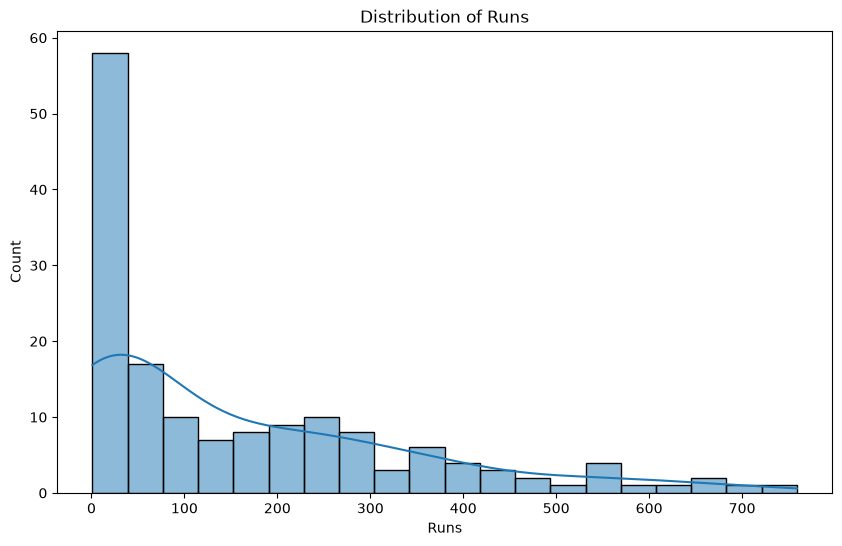

In [57]:
#historical data analysis (Runs)
plt.figure(figsize=(10,6))
sns.histplot(bat_df['Runs'], bins=20, kde=True) 
plt.title('Distribution of Runs')
plt.show()

In [61]:
# High Strike Rate and 6s Filter ( strike rate > 150 and 6's > 30)
bat_df_filtered = (bat_df[(bat_df['SR'] > 150) & (bat_df['6s'] > 30)])
bat_df_filtered

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s,BoundaryRuns
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38,504
4,Mitchell Marsh,LSG,627,13,13,0,117,48.23,383,163.70,1,6,56,37,446
5,Shreyas Iyer,PBKS,604,17,17,5,97*,50.33,345,175.07,0,6,43,39,406
10,Nicholas Pooran,LSG,524,14,14,2,87*,43.67,267,196.25,0,5,45,40,420


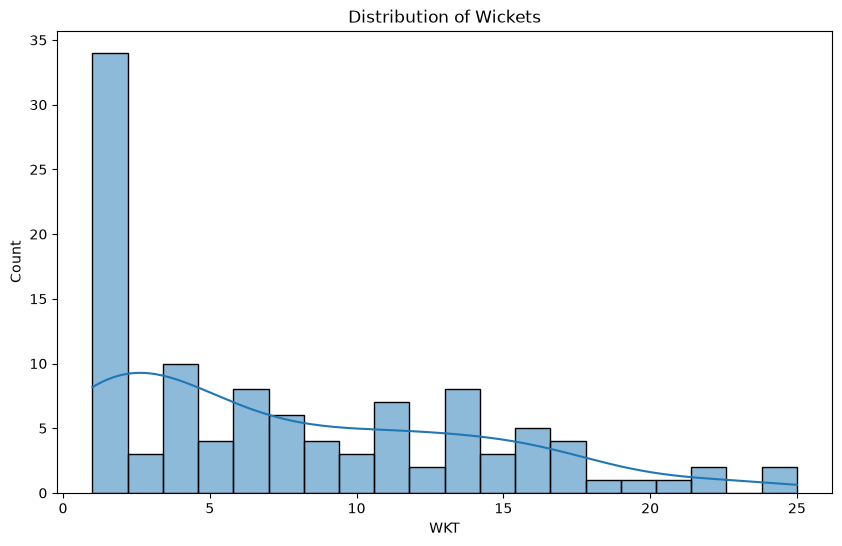

In [58]:
#historical data analysis (Wickets)
plt.figure(figsize=(10,6))
sns.histplot(bowl_df['WKT'], bins=20, kde=True)
plt.title('Distribution of Wickets')
plt.show()

## Bowling Analysis

In [36]:
# Check the columns in the bowling DataFrame
bowl_df.columns

Index(['Player Name', 'Team', 'WKT', 'MAT', 'INN', 'OVR', 'RUNS', 'BBI', 'AVG',
       'ECO', 'SR', '4W', '5W'],
      dtype='str')

In [63]:
# Top 10 Wicket Takers
bowl_df_sorted= bowl_df.sort_values(by='WKT',ascending=False)
bowl_df_sorted.head(10)

,Player Name,Team,WKT,MAT,INN,OVR,RUNS,BBI,AVG,ECO,SR,4W,5W
0,Prasidh Krishna,GT,25,15,15,59.0,488,41/4,19.52,8.27,14.16,1,0
1,Noor Ahmad,CSK,24,14,14,50.0,408,18/4,17.00,8.16,12.50,2,0
2,Josh Hazlewood,RCB,22,12,12,44.0,386,33/4,17.54,8.77,12.00,1,0
3,Trent Boult,MI,22,16,16,57.4,517,26/4,23.50,8.96,15.72,1,0
4,Arshdeep Singh,PBKS,21,17,16,58.2,518,16/3,24.66,8.88,16.66,0,0
5,Sai Kishore,GT,19,15,15,42.3,393,30/3,20.68,9.24,13.42,0,0
6,Jasprit Bumrah,MI,18,12,12,47.2,316,22/4,17.55,6.67,15.77,1,0
7,Varun Chakaravarthy,KKR,17,13,13,50.0,383,22/3,22.52,7.66,17.64,0,0
8,Krunal Pandya,RCB,17,15,15,46.0,379,45/4,22.29,8.23,16.23,1,0
9,Bhuvneshwar Kumar,RCB,17,14,14,52.0,483,33/3,28.41,9.28,18.35,0,0


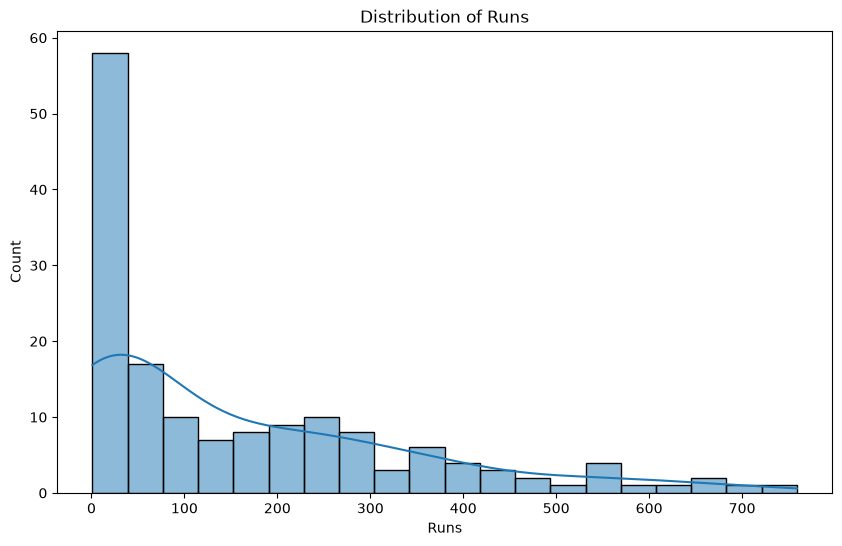

In [65]:
#historical data analysis (Runs)
plt.figure(figsize=(10,6))
sns.histplot(bat_df['Runs'], bins=20, kde=True)
plt.title('Distribution of Runs')       
plt.show()

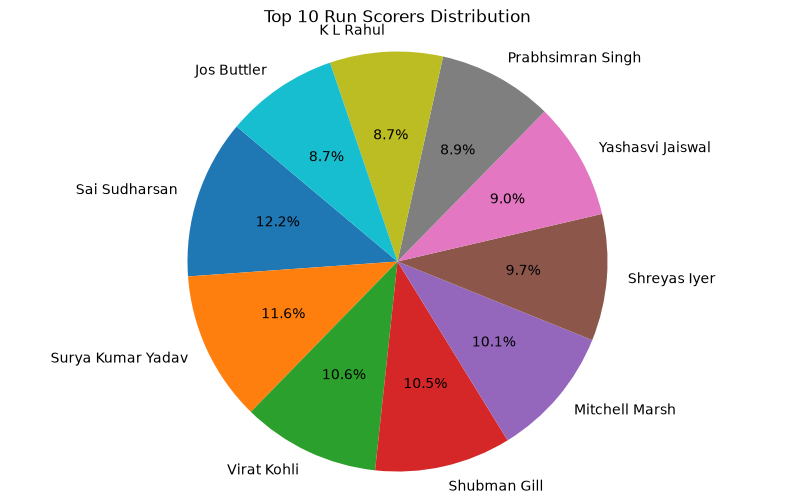

In [67]:
#pie chart for top 10 run scorers
top_10_runs = bat_df_sorted.head(10)
plt.figure(figsize=(10,6))
plt.pie(
    top_10_runs['Runs'],
    labels=top_10_runs['Player Name'],
    autopct='%1.1f%%',
    startangle=140
)
plt.title('Top 10 Run Scorers Distribution')
plt.axis('equal')  
plt.show()

In [78]:
# Statistical Calculations descriptive analysis  (Economy mean,max wickets, average median)
bowl_df['ECO'].min()
bowl_df['ECO'].max()
bowl_df['WKT'].mean()
bowl_df['WKT'].median()


np.float64(6.0)

In [93]:
# Filter Bowlers with Good Economy and Strike Rate  economy < 7 and strike rate < 15

# Filter bowlers with good economy and strike rate
bowl_df[(bowl_df['ECO'] < 7) & (bowl_df['SR'] < 20)]




,Player Name,Team,WKT,MAT,INN,OVR,RUNS,BBI,AVG,ECO,SR,4W,5W
6,Jasprit Bumrah,MI,18,12,12,47.2,316,22/4,17.55,6.67,15.77,1,0


## Combined Analysis

In [98]:
# Merge Batting and Bowling Data
All_df = pd.merge(
    bat_df,
    bowl_df,
    on='Player Name',
    how='outer',
  
)
All_df.head()

,Player Name,Team_x,Runs,Matches,Inn,No,HS,AVG_x,BF,SR_x,...,MAT,INN,OVR,RUNS,BBI,AVG_y,ECO,SR_y,4W,5W
0,Abdul Samad,LSG,164.0,13.0,12.0,4.0,45,20.50,93.0,176.34,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Abhinav Manohar,SRH,61.0,8.0,5.0,0.0,43,12.20,61.0,100.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Abhishek Sharma,SRH,439.0,14.0,13.0,0.0,141,33.77,227.0,193.39,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abishek Porel,DC,301.0,13.0,13.0,1.0,51,25.08,205.0,146.82,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Adam Zampa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,2.0,8.0,94.0,46/1,47.0,11.75,24.0,0.0,0.0


In [99]:
#checking null values in the merged dataframe
All_df.isnull().sum()

Player Name     0
Team_x         37
Runs           37
Matches        37
Inn            37
No             37
HS             37
AVG_x          37
BF             37
SR_x           37
100s           37
50s            37
4s             37
6s             37
Team_y         85
WKT            85
MAT            85
INN            85
OVR            85
RUNS           85
BBI            85
AVG_y          85
ECO            85
SR_y           85
4W             85
5W             85
dtype: int64

In [101]:
#fixing null values in the merged dataframe
# Fix missing values in the merged dataframe without breaking string columns
for col in All_df.columns:
    if pd.api.types.is_numeric_dtype(All_df[col]):
        All_df[col] = All_df[col].fillna(0)
    else:
        All_df[col] = All_df[col].fillna("")

All_df.head()

,Player Name,Team_x,Runs,Matches,Inn,No,HS,AVG_x,BF,SR_x,...,MAT,INN,OVR,RUNS,BBI,AVG_y,ECO,SR_y,4W,5W
0,Abdul Samad,LSG,164.0,13.0,12.0,4.0,45,20.50,93.0,176.34,...,0.0,0.0,0.0,0.0,,0.0,0.00,0.0,0.0,0.0
1,Abhinav Manohar,SRH,61.0,8.0,5.0,0.0,43,12.20,61.0,100.00,...,0.0,0.0,0.0,0.0,,0.0,0.00,0.0,0.0,0.0
2,Abhishek Sharma,SRH,439.0,14.0,13.0,0.0,141,33.77,227.0,193.39,...,0.0,0.0,0.0,0.0,,0.0,0.00,0.0,0.0,0.0
3,Abishek Porel,DC,301.0,13.0,13.0,1.0,51,25.08,205.0,146.82,...,0.0,0.0,0.0,0.0,,0.0,0.00,0.0,0.0,0.0
4,Adam Zampa,,0.0,0.0,0.0,0.0,,,0.0,0.00,...,2.0,2.0,8.0,94.0,46/1,47.0,11.75,24.0,0.0,0.0


In [102]:
#after fixing null values, check again
All_df.isnull().sum()

Player Name    0
Team_x         0
Runs           0
Matches        0
Inn            0
No             0
HS             0
AVG_x          0
BF             0
SR_x           0
100s           0
50s            0
4s             0
6s             0
Team_y         0
WKT            0
MAT            0
INN            0
OVR            0
RUNS           0
BBI            0
AVG_y          0
ECO            0
SR_y           0
4W             0
5W             0
dtype: int64

In [105]:
#merage data analysis (Runs and Wickets) And FInding All-rounders player with good runs and wickets
All_rounder_df=pd.merge(bat_df,bowl_df,on='Player Name',how='inner')


In [115]:
# Identify All-rounders (Runs > 200, wickets >10) for merged dataframe
All_rounder_df[(All_rounder_df['Runs'] > 200) & (All_rounder_df['WKT'] > 10)]


,Player Name,Team_x,Runs,Matches,Inn,No,HS,AVG_x,BF,SR_x,...,INN,OVR,RUNS,BBI,AVG_y,ECO,SR_y,4W,5W,All-rounder Score
5,Sunil Narine,KKR,246,12,12,1,44,22.36,144,170.83,...,12,45.0,351,13/3,29.25,7.80,22.5,0,0,258
7,Hardik Pandya,MI,224,15,12,3,48*,24.89,137,163.50,...,14,35.0,342,36/5,24.42,9.77,15.0,0,1,238


In [109]:
# All-rounder Score  (Max runs, max wickets) for merged dataframe
All_rounder_df['All-rounder Score'] = All_rounder_df['Runs'] + All_rounder_df['WKT']
All_rounder_df.sort_values(by='All-rounder Score', ascending=False, inplace=True)
All_rounder_df.head(10) 


,Player Name,Team_x,Runs,Matches,Inn,No,HS,AVG_x,BF,SR_x,...,INN,OVR,RUNS,BBI,AVG_y,ECO,SR_y,4W,5W,All-rounder Score
5,Sunil Narine,KKR,246,12,12,1,44,22.36,144,170.83,...,12,45.0,351,13/3,29.25,7.80,22.5,0,0,258
7,Hardik Pandya,MI,224,15,12,3,48*,24.89,137,163.50,...,14,35.0,342,36/5,24.42,9.77,15.0,0,1,238


In [112]:
#Try to find orange cap and purple cap winner based on the merged data
All_df['Orange Cap Winner'] = All_df['Runs'].max()
All_df['Purple Cap Winner'] = All_df['WKT'].max()
print("Orange Cap Winner:", All_df['Player Name'][All_df['Runs'] == All_df['Orange Cap Winner']].values[0])
print("Purple Cap Winner:", All_df['Player Name'][All_df['WKT'] == All_df['Purple Cap Winner']].values[0])

Orange Cap Winner: Sai Sudharsan
Purple Cap Winner: Prasidh Krishna


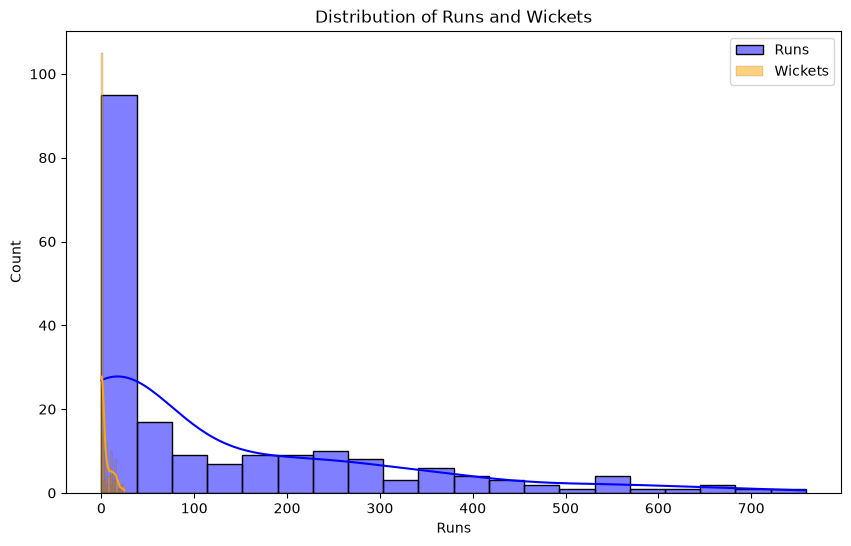

In [117]:
#historical data analysis (Runs and Wickets) for merged dataframe
plt.figure(figsize=(10,6))
sns.histplot(All_df['Runs'], bins=20, kde=True, color='blue', label='Runs')
sns.histplot(All_df['WKT'], bins=20, kde=True, color='orange', label='Wickets')
plt.title('Distribution of Runs and Wickets')
plt.legend()
plt.show()

Insights
1. Best All rounder players are Sunil Narine and Hardik Pandya
2. Best Batsman Sai Sudharsan	
3. Best Bowler Jasprit Bumrah	
4. Orange Cap Winner: Sai Sudharsan
5. Purple Cap Winner: Prasidh Krishna